# Tutorial 2. A DC distribution feeder: cable, DC link, converter and loads

![A DC distribution feeder](../tutorials/images/t02_hero.png)

**Scope:** energy distribution, electrical engineering. **Components:**
`VoltageSource`, `Resistor`, `Inductor`, `Capacitor`, `Transformer`,
`CurrentSource`, `Ground`.

## The asset

A 750 V DC feeder runs 2 km from a substation to a cluster of buildings. At the
far end a DC link capacitor and a DC/DC converter step the voltage down to 48 V
for the loads. The distribution engineer wants to know:

- **Voltage regulation.** How far does the 48 V bus sag when the load steps from
  20 kW to 60 kW, and how long does it take to recover?
- **Oscillation.** The cable inductance and the DC link capacitance form a
  resonant circuit. Is it damped enough, or does a load step ring?

![Single-line diagram](../tutorials/images/t02_pd.png)

IEC 60617 symbols: the source, the cable as a resistor and an inductor, the DC
link capacitor, the ideal converter as a transformer, the load as a current
source with a leakage resistance in parallel. Two voltage transmitters mark the
quantities we will watch.

## Step 1. Build the feeder

Every element is a stock electrical component. The DC/DC converter is an ideal
`Transformer` between two electrical sides: it carries power without loss and
scales voltage by its ratio, which is what a converter does on the time scale of
the feeder.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.electrical import (
    Capacitor,
    CurrentSource,
    Ground,
    Inductor,
    Resistor,
    VoltageSource,
)
from otwin.components.twoport import Transformer

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

source = VoltageSource(None, name="substation")  # V, an input
cable_r = Resistor(0.20, name="cable_r")  # ohm, 2 km of 240 mm2 aluminium, both ways
cable_l = Inductor(2e-3, name="cable_l")  # H
dc_link = Capacitor(10e-3, voltage=750.0, name="dc_link")  # F, precharged
converter = Transformer(
    48.0 / 750.0, domain_1="electrical", domain_2="electrical", name="converter"
)
load = CurrentSource(None, name="load")  # A at 48 V, an input
leak = Resistor(48.0 / 2.0, name="leak")  # a 2 A standing load: lighting, controls
gnd = Ground(name="gnd")

feeder = otwin.System(source, cable_r, cable_l, dc_link, converter, load, leak, gnd)
feeder.connect(source.p, cable_r.p)
feeder.connect(cable_r.n, cable_l.p)
feeder.connect(cable_l.n, dc_link.p, converter.p1)
feeder.connect(
    converter.p2, load.n, leak.p
)  # load.n on the bus: + current is drawn from it
feeder.connect(source.n, dc_link.n, converter.n1, converter.n2, load.p, leak.n, gnd.port)
model = otwin.compile(feeder)
print(model.summary())

System: system

Components:
  substation                   voltage_source [electrical]
  cable_r                      resistor [electrical]
  cable_l                      inductor [electrical]
  dc_link                      capacitor [electrical]
  converter                    transformer [electrical]
  load                         current_source [electrical]
  leak                         resistor [electrical]
  gnd                          ground [any]

States:
  cable_l.flux                 flux linkage [Wb]  x0 = 0
  dc_link.charge               charge [C]  x0 = 7.5

Inputs:
  substation                   voltage [V]
  load                         current [A]

Parameters:
  cable_r.resistance           0.2          ohm
  cable_l.inductance           0.002        H
  dc_link.capacitance          0.01         F
  converter.ratio              0.064        
  leak.resistance              24           ohm

Outputs: 28 named quantities (model.outputs())
Representation: port-hamiltonian
B

Two states: the flux in the cable inductance and the charge on the DC link. The
converter adds no state; it is an algebraic coupling the compiler puts in the
interconnection matrix `J`, never in the dissipation `R`. The model is
`port-hamiltonian`: every element is power-conjugate, so the energy audit here is
a first-law statement.

## Step 2. The load step

The substation holds 750 V. The load draws 20 kW at 48 V (417 A) and steps to
60 kW (1250 A) at t = 50 ms. The natural frequency of the cable and the link is
1/(2π√(LC)) ≈ 36 Hz, so we resolve the response with a 50 µs step for 0.4 s.

In [ ]:
t = np.arange(0.0, 0.4, 5e-5)
load_current = np.where(t < 0.05, 20e3 / 48, 60e3 / 48)
run = model.simulate(
    t=t, inputs={"substation": 750.0, "load": load_current}, solver="rk4"
)

v_bus = run["converter.side2.voltage"]
v_link = run["dc_link.voltage"]
after = t >= 0.05
print(
    f"natural frequency 1/(2 pi sqrt(LC)) = {1 / (2 * np.pi * np.sqrt(2e-3 * 10e-3)):.1f} Hz, "
    f"damping ratio R/2 sqrt(C/L) = {0.20 / 2 * np.sqrt(10e-3 / 2e-3):.2f}"
)
print(
    f"48 V bus: {v_bus[0]:.2f} V before the step, minimum {v_bus[after].min():.2f} V, "
    f"settles at {v_bus[-1]:.2f} V"
)
print(
    f"DC link: {v_link[0]:.1f} V before, minimum {v_link[after].min():.1f} V, settles at {v_link[-1]:.1f} V"
)
drop = 750.0 - v_link[-1]
print(
    f"steady cable drop {drop:.1f} V = I R with I = {run['cable_r.current'][-1]:.0f} A, "
    f"cable loss {run['cable_r.power'][-1] / 1e3:.1f} kW"
)

natural frequency 1/(2 pi sqrt(LC)) = 35.6 Hz, damping ratio R/2 sqrt(C/L) = 0.22
48 V bus: 48.00 V before the step, minimum 45.98 V, settles at 46.97 V
DC link: 750.0 V before, minimum 718.4 V, settles at 734.0 V
steady cable drop 16.0 V = I R with I = 80 A, cable loss 1.3 kW


The damping ratio is well below one, so the step rings at the natural frequency
before it settles, and the first swing takes the link well below its steady
value. The steady state is Ohm's law: the cable carries the load power over
750 V plus the losses, and the drop across 0.20 Ω is the figure printed. The
48 V bus is the link scaled by the converter ratio, so a 16 V drop on the link
is about 1 V on the bus.

## Step 3. Plot the transient

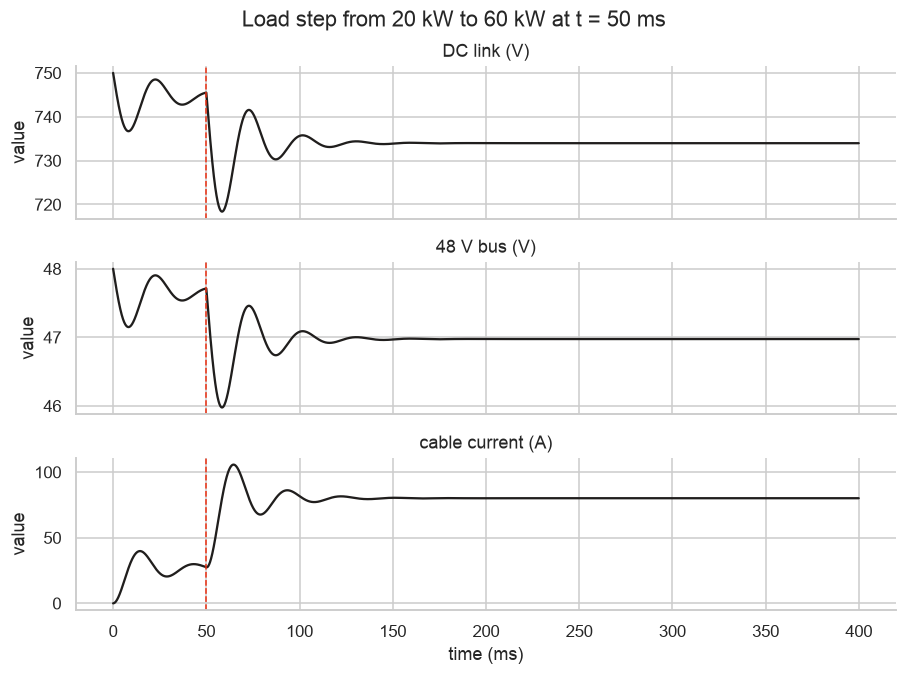

In [ ]:
frame = pd.DataFrame(
    {
        "time (ms)": t * 1e3,
        "DC link (V)": v_link,
        "48 V bus (V)": v_bus,
        "cable current (A)": run["cable_r.current"],
    }
)
long = frame.melt("time (ms)", var_name="signal", value_name="value")
g = sns.relplot(
    data=long,
    x="time (ms)",
    y="value",
    row="signal",
    kind="line",
    height=2.0,
    aspect=4.2,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
for ax in g.axes.flat:
    ax.axvline(50, color="#EC3013", ls="--", lw=1)
g.figure.suptitle("Load step from 20 kW to 60 kW at t = 50 ms", y=1.02)

The ring at about 36 Hz decays within a few cycles. The cable current overshoots
before settling, which is the inductor resisting the change.

## Step 4. Energy accounting

A port-Hamiltonian model keeps the books: the power supplied at the ports equals
the rate of change of stored energy plus the power dissipated. The trajectory
records all three, so the check is one line.

In [ ]:
balance = run.energy_balance()
print(
    "largest step on which stored energy rose by more than the ports supplied:",
    f"{balance['max_violation']:.3e} J",
)
dissipated = run["cable_r.power"] + run["leak.power"]
delta_e = run.energy[-1] - run.energy[0]
integral = np.trapezoid(run.supplied_power - dissipated, t)
print(
    f"stored energy changed by {delta_e:.2f} J; integral of (port power - losses) = {integral:.2f} J; "
    f"difference {abs(delta_e - integral):.3f} J against {np.trapezoid(np.abs(run.supplied_power), t):.0f} J exchanged"
)

largest step on which stored energy rose by more than the ports supplied: 9.817e-01 J
stored energy changed by -112.48 J; integral of (port power - losses) = -113.48 J; difference 0.994 J against 1177 J exchanged


The change in stored energy equals the integral of port power less losses to
about a joule against the kilojoule exchanged, and no step created more than a
joule. The residue is the explicit `rk4` integrator; the implicit midpoint rule
makes the discrete balance exact, at the cost of a Newton solve per step. Use this check whenever you add an element: a residual that grows means
a law with the wrong sign, and the compiler would have warned at compile time if
a dissipation were negative.

## Step 5. Sweep the cable

What if the feeder were a thinner cable? Change parameters without recompiling.

In [ ]:
rows = []
for r_cable in (0.10, 0.20, 0.40, 0.80):
    variant = model.with_parameters(**{"cable_r.resistance": r_cable})
    out = variant.simulate(
        t=t, inputs={"substation": 750.0, "load": load_current}, solver="rk4"
    )
    rows.append(
        {
            "R_cable (ohm)": r_cable,
            "min 48 V bus (V)": out["converter.side2.voltage"][after].min(),
            "steady 48 V bus (V)": out["converter.side2.voltage"][-1],
            "cable loss (kW)": out["cable_r.power"][-1] / 1e3,
        }
    )
print(pd.DataFrame(rows).round(2).to_string(index=False))

 R_cable (ohm)  min 48 V bus (V)  steady 48 V bus (V)  cable loss (kW)
           0.1             46.21                47.49             0.64
           0.2             45.98                46.97             1.28
           0.4             45.40                45.95             2.57
           0.8             43.89                43.90             5.13


A heavier cable costs copper and saves losses; the table is the trade-off the
distribution engineer prices. Note that the minimum of the ringing is set mostly
by L and C, the steady drop by R.

## What to take from this

- The `>>` chain and `connect` are the whole modelling language; the compiler
  writes the circuit equations.
- A `Transformer` couples two sides losslessly and lives in `J`; the compiler
  reports the model as `port-hamiltonian` when every element is power-conjugate.
- `with_parameters` gives a variant without recompiling, which is also how
  `fit_parameters` works when you later fit the model to measurements.

Next: [Tutorial 3](03_vehicle_suspension.md) leaves the electrical domain for the
mechanical one, with the same two rules.